# What Chemistry Tells Us About Wine Quality


**Author:** Grace Oladosu


**Question:** Which chemical properties are associated with higher   quality scores in red and white wine?


**Data:** 6,497 Portuguese wines (1,599 red wine and 4,898 white wine) with 11 chemical measurements and quality score from 3 to 9, assigned by tasters.


**Tools:** Python, pandas, matplotlib, seaborn

**Source:** "Wine_Quality_Data" by Ghassen Khaled, Kaggle (CC0: Public Domain). Based on the Wine Quality dataset by Cortez et al. (2009), UCI Machine Learning Repository.

## Key findings

- Alcohol content had the strongest positive link with quality in both red (r = 0.48) and white wines (r = 0.46).
- The next factors differed by type: volatile acidity (r = -0.40) for red, and density (r = -0.34) and chlorides (r = -0.22) for white.
- In white wines, density is closely tied to alcohol and sugar (r = -0.76 and 0.82), so its link to quality may partly reflect them rather than being a seperate effect.
- These are correlations, not proof of cause.


## 1. Loading the data

The red and white wine files are combined into one table, 
with a "wine_type" column to differentiate them.

In [1]:

import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

data_folder = Path("data")
red = pd.read_csv(data_folder / "winequality-red.csv", sep=";")
white = pd.read_csv(data_folder / "winequality-white.csv", sep=";")

wines = pd.concat(
    [red.assign(wine_type="Red"), white.assign(wine_type="White")],
    ignore_index=True
)

## 2. Cleaning
There were no missing values. I found 1,177 exact duplicate rows and removed them so repeated records would not bias the results,
leaving 5,320 wines (3,961 white, 1,359 red).

In [2]:
rows_before = len(wines)
wines = wines.drop_duplicates().reset_index(drop=True)
rows_after= len(wines)

print("Rows before: ", rows_before)
print("Rows after: ", rows_after)
print("Removed:", rows_before - rows_after)
print(wines["wine_type"].value_counts())

Rows before:  6497
Rows after:  5320
Removed: 1177
wine_type
White    3961
Red      1359
Name: count, dtype: int64


## 3. How are quality scores distributed?

Most wines score 5 or 6. Red wines peak at 5, white wines at 6, and only white wines reach the highest scores (9). Shares are shown as percentages because there are more white wines than red wines.

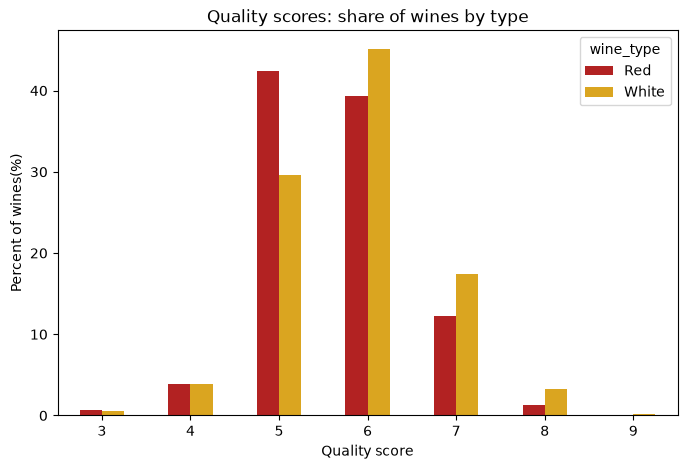

In [3]:
counts = wines.groupby(["quality", "wine_type"]).size().unstack(fill_value=0)
percent = counts/ counts.sum() * 100

percent.plot(kind="bar", figsize=(8, 5), color=["firebrick", "goldenrod"])
plt.title("Quality scores: share of wines by type")
plt.xlabel("Quality score")
plt.ylabel("Percent of wines(%)")
plt.xticks(rotation=0)
plt.savefig("quality_by_wine_type.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Which properties go with quality?

Alcohol has the strongest positive link with quality in both types.
After that, red and white differ: volatile acidity, sulphates and 
citric acid matter more for red, while density and chlorides stand 
out for white. These are correlations, not proof of cause.

In [4]:
numeric = wines.drop(columns="wine_type")
correlations = numeric.corr()["quality"].drop("quality").sort_values()
print(correlations.round(2))

for wine in ["Red", "White"]:
    subset = wines[wines["wine_type"] == wine].drop(columns="wine_type")
    print(wine)
    print(subset.corr()["quality"].drop("quality").sort_values().round(2))
    print()  

density                -0.33
volatile acidity       -0.27
chlorides              -0.20
fixed acidity          -0.08
residual sugar         -0.06
total sulfur dioxide   -0.05
pH                      0.04
sulphates               0.04
free sulfur dioxide     0.05
citric acid             0.10
alcohol                 0.47
Name: quality, dtype: float64
Red
volatile acidity       -0.40
density                -0.18
total sulfur dioxide   -0.18
chlorides              -0.13
pH                     -0.06
free sulfur dioxide    -0.05
residual sugar          0.01
fixed acidity           0.12
citric acid             0.23
sulphates               0.25
alcohol                 0.48
Name: quality, dtype: float64

White
density                -0.34
chlorides              -0.22
volatile acidity       -0.19
total sulfur dioxide   -0.18
fixed acidity          -0.12
residual sugar         -0.12
citric acid             0.01
free sulfur dioxide     0.01
sulphates               0.05
pH                      0.12
a

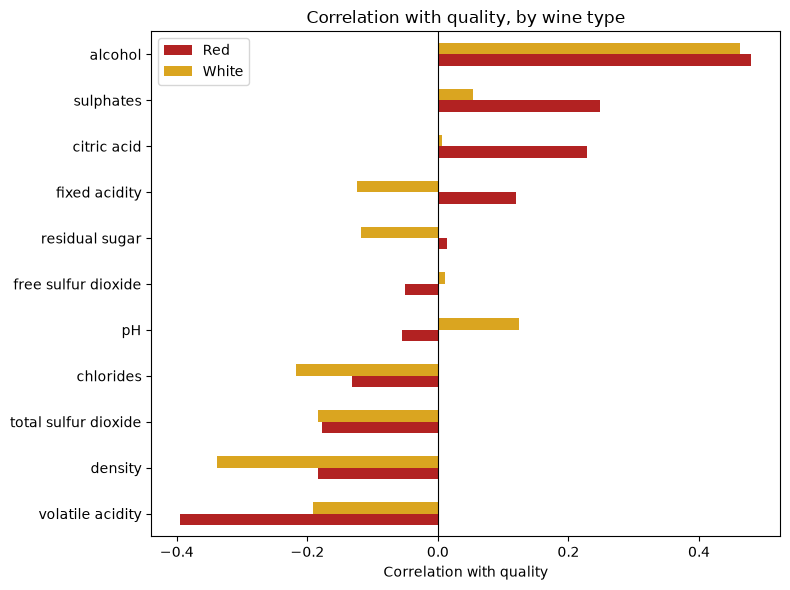

In [5]:
corr = pd.DataFrame({
    wine: wines[wines["wine_type"] == wine]
          .drop(columns="wine_type").corr()["quality"].drop("quality")
    for wine in ["Red", "White"]
}).sort_values("Red")

corr.plot(kind="barh", figsize=(8, 6), color=["firebrick", "goldenrod"])
plt.title("Correlation with quality, by wine type")
plt.xlabel("Correlation with quality")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig("correlation_by_wine_type.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Alcohol and quality

Median alcohol rises from quality 5 to quality 8 in both types.
Some quality 5 wines have very high alcohol, so alcohol is
linked to quality on average but does not decide it.


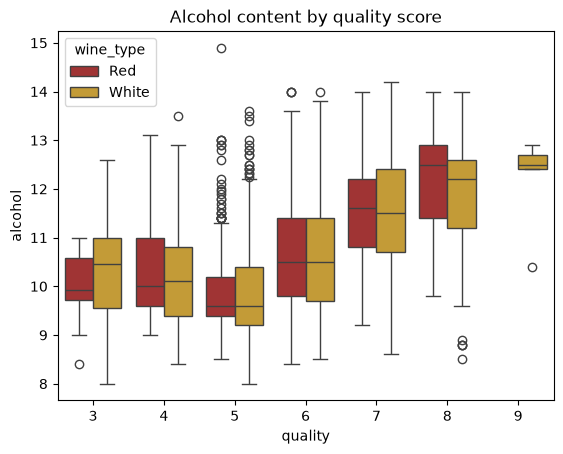

In [6]:
sns.boxplot(data=wines, x="quality", y="alcohol", hue="wine_type",
            palette=["firebrick", "goldenrod"])
plt.title("Alcohol content by quality score")
plt.show() 

## 6. Why density appears in the results

Density is closely tied to alcohol (lighter ethanol lowers density) and residual sugar (heavier sugar raises density), especially in white wine (r = -0.76 and 0.82). Its link to quality may therefore partly reflect these two rather than being a seperate effect.

In [7]:

for wine in ["Red", "White"]:
    subset = wines[wines["wine_type"] == wine]
    alcohol_r = subset["alcohol"].corr(subset["density"]).round(2)
    sugar_r = subset["residual sugar"].corr(subset["density"]).round(2)
    print(wine)
    print("alcohol vs density:", alcohol_r)
    print("residual sugar vs density:", sugar_r)
    print()

Red
alcohol vs density: -0.5
residual sugar vs density: 0.32

White
alcohol vs density: -0.76
residual sugar vs density: 0.82



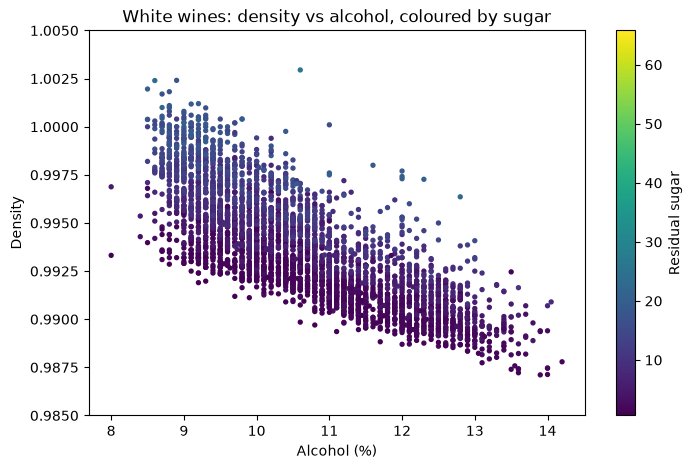

In [8]:
white = wines[wines["wine_type"] == "White"]
plt.figure(figsize=(8, 5))
plt.scatter(white["alcohol"], white["density"],
            c=white["residual sugar"], cmap="viridis", s=8)
plt.colorbar(label="Residual sugar")
plt.xlabel("Alcohol (%)")
plt.ylabel("Density")
plt.ylim(0.985, 1.005)
plt.title("White wines: density vs alcohol, coloured by sugar")
plt.savefig("white_density_alcohol_sugar.png", dpi=200, bbox_inches="tight")
plt.show()

## Conclusion

Across 5,320 wines, alcohol content was the strongest chemical factor associated with quality in both red (r = 0.48) and white wines (r = 0.46). Red and white wines differed in what came next: volatile acidity, sulphates and citric acid mattered more for red, while density and chlorides stood out for white. In white wines, density was closely tied to alcohol (r = -0.76) and residual sugar (r = 0.82), so its link to quality may partly reflect those two rather than being an independent effect.

## Limitations

These are correlations and do not show that any property causes a higher score. Quality scores are subjective ratings by tasters, and most wines scored 5 or 6, so very low and very high scores (3, 8, 9) contain few wines. After removing 1,177 duplicate rows, red wines made up about a quarter of the data. The data contains no information on grape variety, price, or vintage, which could also affect quality.
I did not test whether density adds any information beyond alcohol and sugar.